# Coverage Is Not Connectivity: New York's EV fast-charging network (final)

SSIE 641 final project: Joubin Zahiri Khameneh, Shamim Sharbaf, Zeinab Davoodmanesh.

This notebook walks through the results question by question, in the order of the report (`paper/report.md`).
Every number comes from the scripts in `scripts/`, which write `results/tables/*.csv`, `results/figures/*.png`
and the `results/*summary.json` files:

| Script | What it adds | Time |
| --- | --- | --- |
| `run_all.py` | Q1, Q2, coverage, heuristic Q3, winter, control, October data | about 3 min |
| `run_structure.py` | biconnectivity, reliability, efficiency, betweenness variants, k-cores, spectral split, communities | about 3 min |
| `run_exact.py` | exact cost of connectivity and cost of robustness on road distances (report Section 7) | about 45 min |
| `run_extended.py` | trips on real routes, Hanig-style coverage, growth over time, regional outages, baselines | about 1 hour |
| `run_learning.py` | optional GNN benchmark (needs PyTorch; not used in the report) | long |

Set `RUN = True` to rebuild the first two. The analysis code lives in `src/evnet/`.

Changes from notebook v3 (`notebooks/ev_network_v3.ipynb`):
- Q3 uses a Steiner-tree heuristic (Takahashi & Matsuyama, 1980) with upper and lower bounds and an exact
  feasibility test, for two objectives (whole network, all city pairs), instead of the greedy search.
- Road distances re-queried from OSRM for all site pairs within 60 miles (data/derived/road_miles_pairs_le60.u16.gz);
  links to new stations use the measured detour factor 1.22 for those distances; 1.2 is kept as a sensitivity check.
- "Big or small" is answered by ports as well as degree.
- Population share corrected: places with 5,000+ people hold 76% of the state, not 92%.
- New: budget against the $175M NEVI allocation, winter range, NYC-excluded and access-capped coverage,
  October 2026 data check.

In [1]:
import json, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUN = False
if RUN:
    for script in ["run_all.py", "run_structure.py"]:
        subprocess.run([sys.executable, str(ROOT / "scripts" / script)], check=True)

TAB, FIG = ROOT / "results" / "tables", ROOT / "results" / "figures"
S = json.load(open(ROOT / "results" / "summary.json"))
pd.set_option("display.max_colwidth", 120)
def t(name): return pd.read_csv(TAB / name)
def f(name):
    if (FIG / name).exists():
        display(Image(filename=str(FIG / name), width=850))
    else:
        print(f"{name} not found: run the script that makes it")
def tt(name):
    if (TAB / name).exists():
        display(t(name))
    else:
        print(f"{name} not found: run the script that makes it")

## 1. Data

stations: 755 | fast ports: 3408 | sites: 754 | CCS sites: 661
places >= 5000: 362 | people: 15312729 | share of NY population: 75.8%
NYC's share of population-weighted city pairs: 73%
candidate L1/L2 locations: 4756
distances: OSRM road network


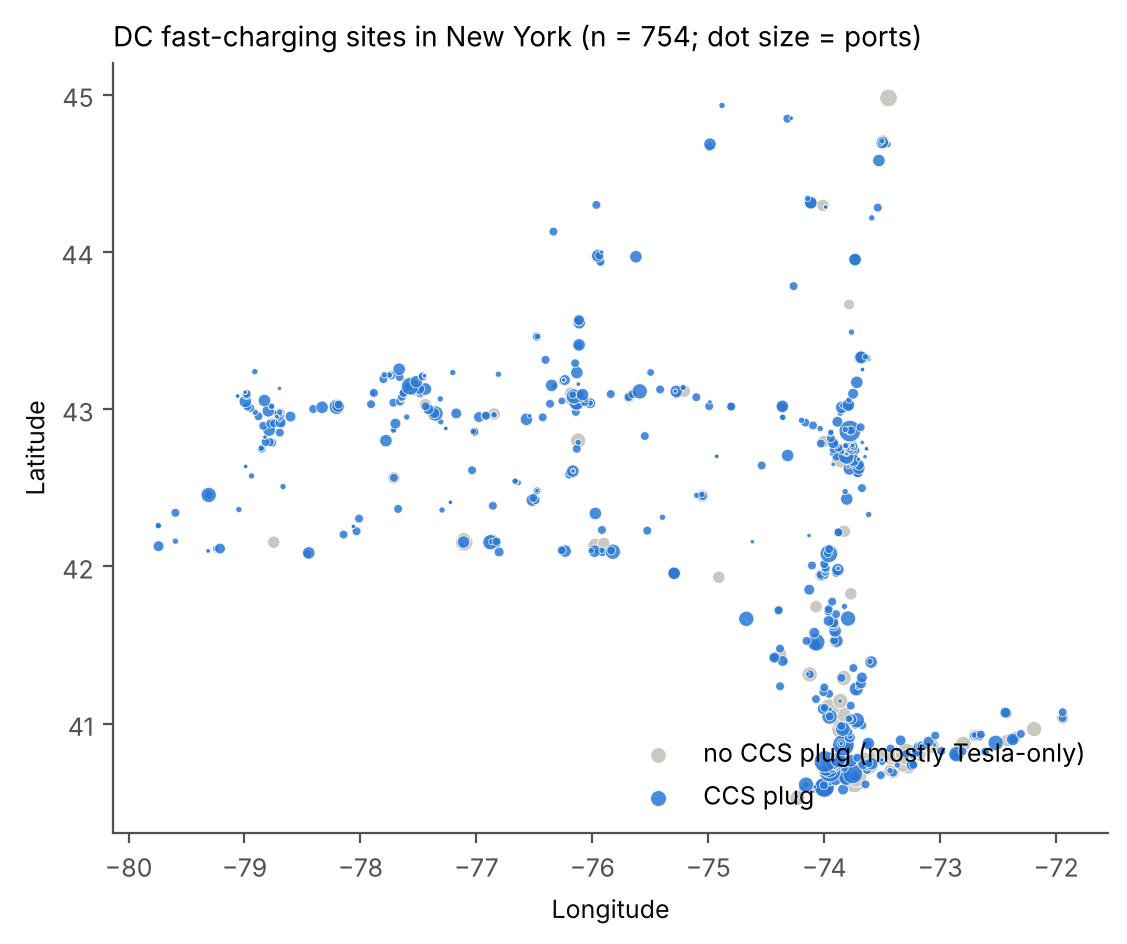

In [2]:
print("stations:", S["stations"], "| fast ports:", S["fast_ports"], "| sites:", S["sites"], "| CCS sites:", S["ccs_sites"])
print("places >= 5000:", S["places_5000"], "| people:", S["pop_places_5000"],
      f"| share of NY population: {S['share_state_pop_in_places_5000']:.1%}")
print(f"NYC's share of population-weighted city pairs: {S['nyc_share_of_pair_weight']:.0%}")
print("candidate L1/L2 locations:", S["candidates"])
print("distances:", S["distance_source"])
f("figS1_sites_map.png")

## 2. Q1: When does the network split?

The whole network is one piece from the longest link of its minimum spanning tree: 43.5 road miles.

{'all_road': 43.5, 'all_straight_x1.2': 43.1, 'all_straight_xfactor': 43.8, 'ccs_road': 43.5} | weakest link: Saranac Lake - Malone


,Unnamed: 0,all_road,all_road.1,all_road.2,all_straight_x1.2,all_straight_x1.2.1,all_straight_x1.2.2,all_straight_xfactor,all_straight_xfactor.1,all_straight_xfactor.2,ccs_road,ccs_road.1,ccs_road.2
0,NaN,miles,from,to,miles,from,to,miles,from,to,miles,from,to
1,0.0,43.5,Saranac Lake,Malone,43.11515633669068,Saranac Lake,Malone,43.83374227563553,Saranac Lake,Malone,43.5,Saranac Lake,Malone
2,1.0,37.15,Malone,Massena,33.85098158813832,Malone,Massena,34.41516461460729,Malone,Massena,37.15,Malone,Massena
3,2.0,34.65,Arkville,TANNERSVILLE,32.08966355076832,Pulaski,Watertown,32.62449127661446,Pulaski,Watertown,37.05,Warrensburg,Indian Lake
4,3.0,33.25,Chestertown,Indian Lake,30.290754956084065,Chestertown,Indian Lake,30.795600872018802,Chestertown,Indian Lake,36.05,Warrensburg,North Hudson
5,4.0,28.3,Pulaski,Watertown,26.32617712014979,Monticello,Roscoe,26.764946738818953,Monticello,Roscoe,34.65,Arkville,TANNERSVILLE
6,5.0,27.1,Monticello,Roscoe,25.878728398204327,Watertown,Cape Vincent,26.310040538174402,Watertown,Cape Vincent,30.85,Hancock,Afton
7,6.0,27.1,Elizabethtown,Lake Placid,25.86353361247827,Roscoe,Arkville,26.294592506019576,Roscoe,Arkville,28.3,Pulaski,Watertown


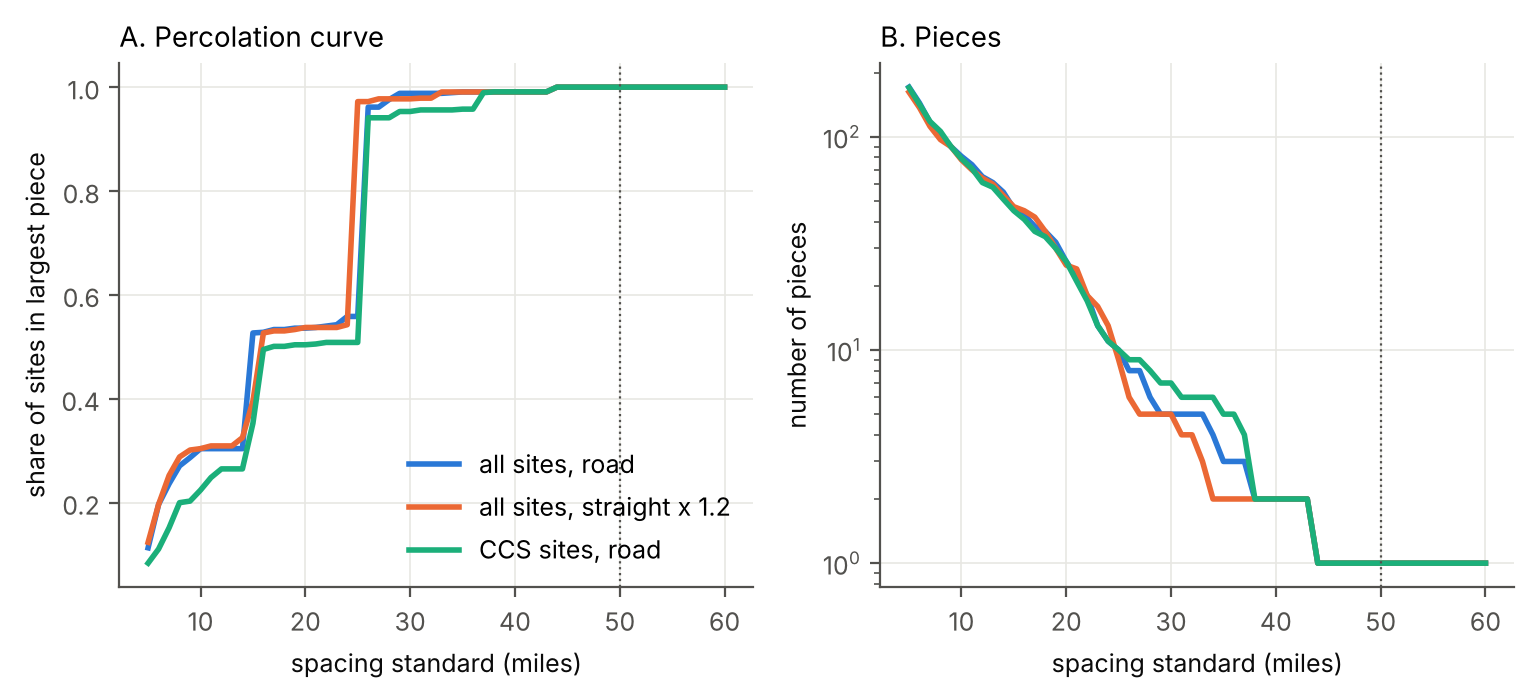

,piece,sites,mean_lat,mean_lon,main_cities
0,1,421,41.61,-73.70,"Queens, Albany, Brooklyn, New York, Latham, Riverhead"
1,2,294,42.85,-77.32,"Rochester, Syracuse, Buffalo, Niagara Falls, Yorkville, Elmira"
2,3,10,42.51,-75.09,"Oneonta, Cooperstown, Afton, Sidney"
3,4,9,44.02,-75.95,"Watertown, West Carthage, Cape Vincent, Alexandria Bay"
4,5,8,44.30,-74.04,"Lake Placid, Saranac Lake"
5,6,5,44.73,-74.97,"Potsdam, Massena"
6,7,2,41.96,-75.29,Hancock
7,8,2,44.85,-74.30,Malone
8,9,1,41.93,-74.91,Roscoe
9,10,1,42.16,-74.62,Arkville


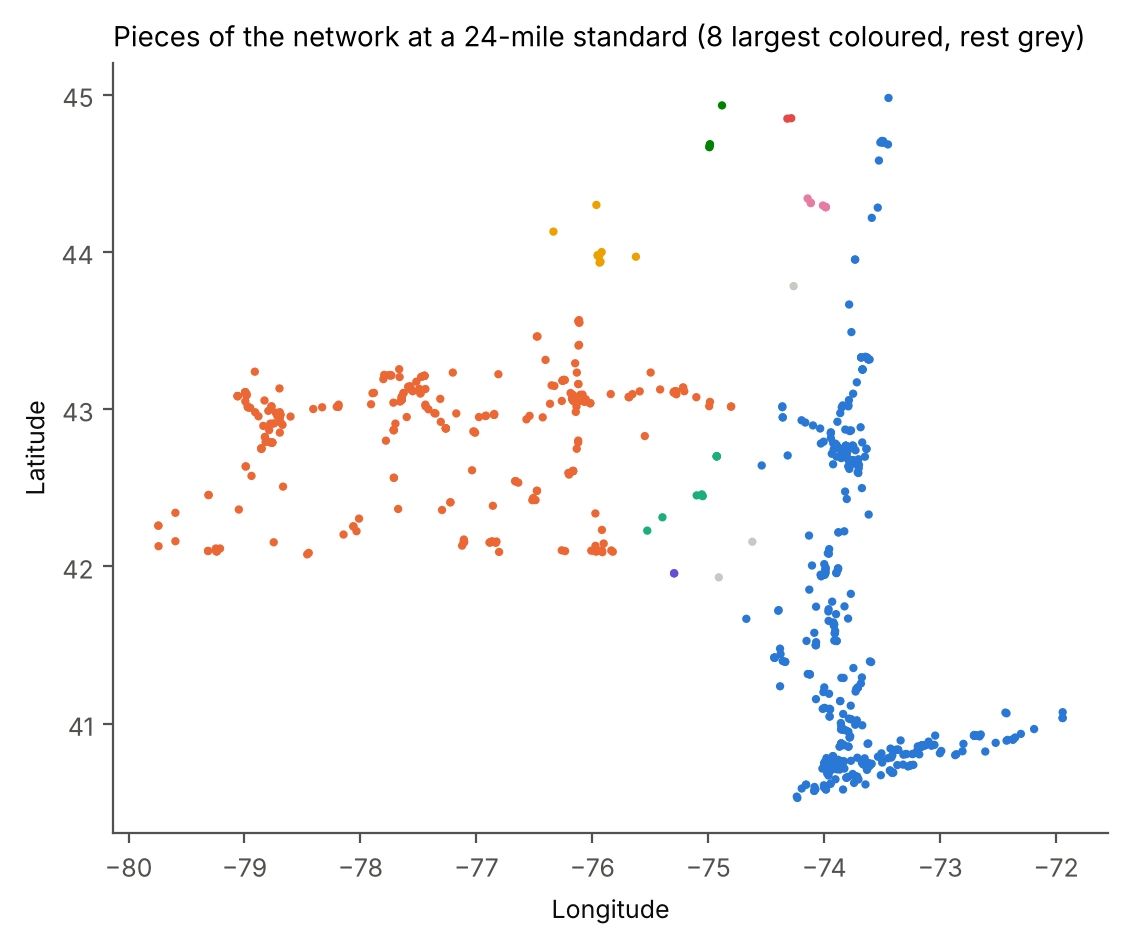

In [3]:
print({k: round(v, 1) for k, v in S["threshold"].items()}, "| weakest link:", S["weakest_link"])
display(t("q1_weakest_links.csv").head(8))
f("fig1_percolation.png")
display(t("q1_pieces_24mi.csv"))
f("fig2_pieces_24mi.png")

## 3. Q2: Which stations hold the network together?

Single points of failure (articulation points) are isolated rural sites: low degree, but typical or large by ports.

,network,miles,id,name,city,operator,degree,ports,sites_cut_off,degree_percentile,ports_percentile
0,all,30,712,"Chestertown, NY - Tesla Supercharger",Chestertown,Tesla,8,6,24,0.046419,0.701592
1,all,30,735,"Peru, NY - Tesla Supercharger",Peru,Tesla,12,8,11,0.108753,0.774536
2,all,30,724,Egglefield Bros,Elizabethtown,FORD_CHARGE,9,2,8,0.067639,0.270557
3,all,30,267,"Monticello, NY - Tesla Supercharger",Monticello,Tesla,9,12,3,0.067639,0.911141
4,all,30,279,"Roscoe, NY - Tesla Supercharger",Roscoe,Tesla,3,8,2,0.009284,0.774536
5,ccs,30,645,"Peru, NY - Tesla Supercharger",Peru,Tesla,11,8,9,0.114977,0.857791
6,ccs,30,290,Simmons Rockwell Ford Hornell NY,Hornell,RED_E,8,4,7,0.072617,0.497731
7,ccs,30,635,Egglefield Bros,Elizabethtown,FORD_CHARGE,8,2,7,0.072617,0.301059
8,all,35,712,"Chestertown, NY - Tesla Supercharger",Chestertown,Tesla,18,6,25,0.137931,0.701592
9,all,35,341,Thorpe's GMC,TANNERSVILLE,EV Connect,29,1,1,0.238727,0.000000


,miles,network,critical_sites,median_degree_all,median_degree_critical,median_ports_all,median_ports_critical,share_tesla_critical
0,25,all,13,42.0,6.0,4.0,4.0,0.230769
1,25,ccs,12,39.0,7.0,4.0,4.0,0.166667
2,30,all,5,50.0,9.0,4.0,8.0,0.800000
3,30,ccs,3,47.0,8.0,4.0,4.0,0.333333
4,35,all,2,58.0,23.5,4.0,3.5,0.500000
5,35,ccs,1,53.0,27.0,4.0,1.0,0.000000
6,40,all,0,66.0,NaN,4.0,NaN,NaN
7,40,ccs,1,62.0,23.0,4.0,2.0,0.000000
8,45,all,1,73.0,11.0,4.0,2.0,0.000000
9,45,ccs,2,68.0,17.0,4.0,2.0,0.000000


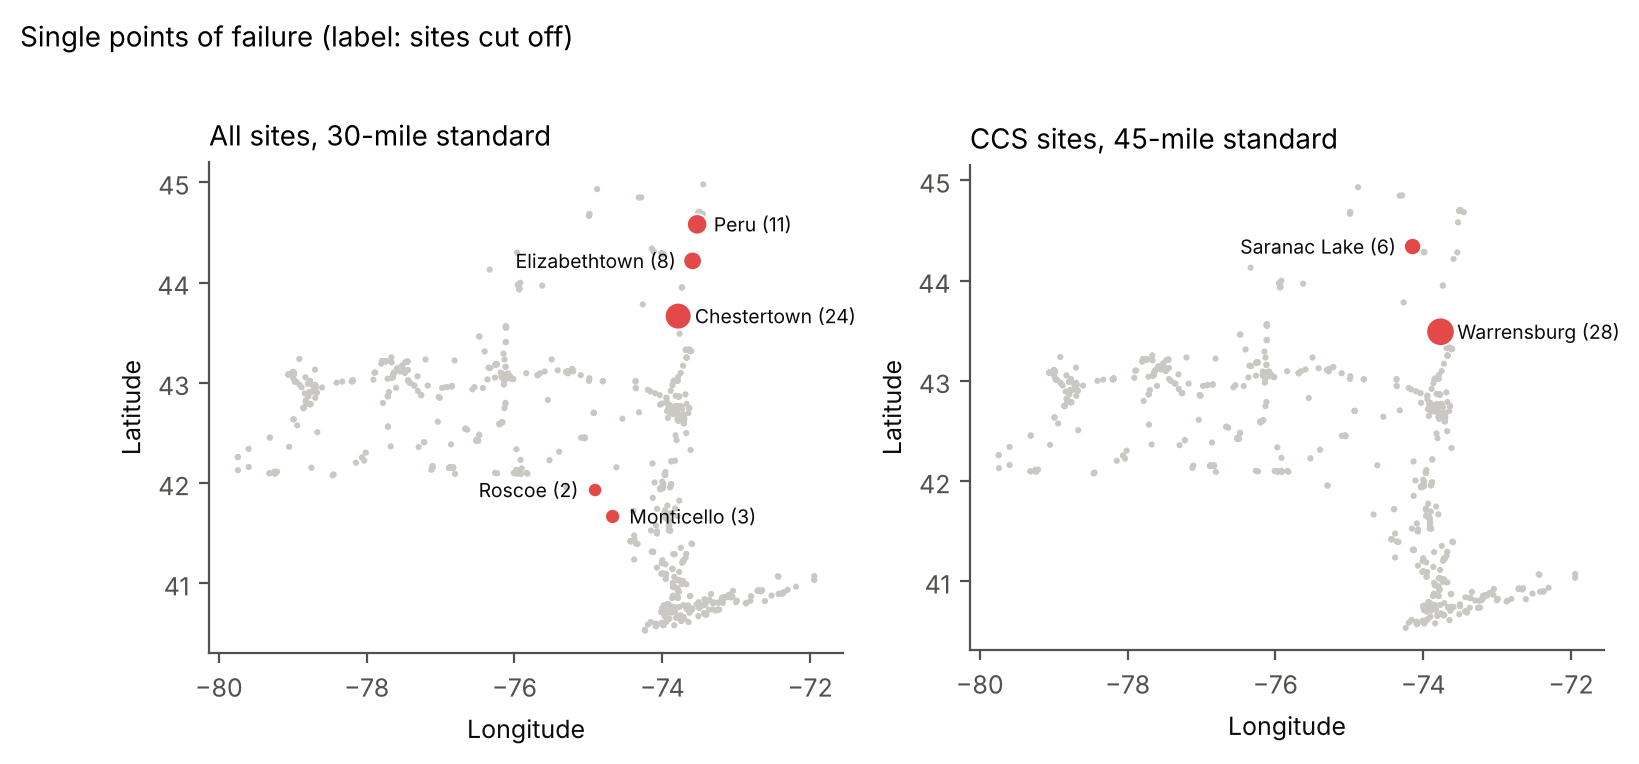

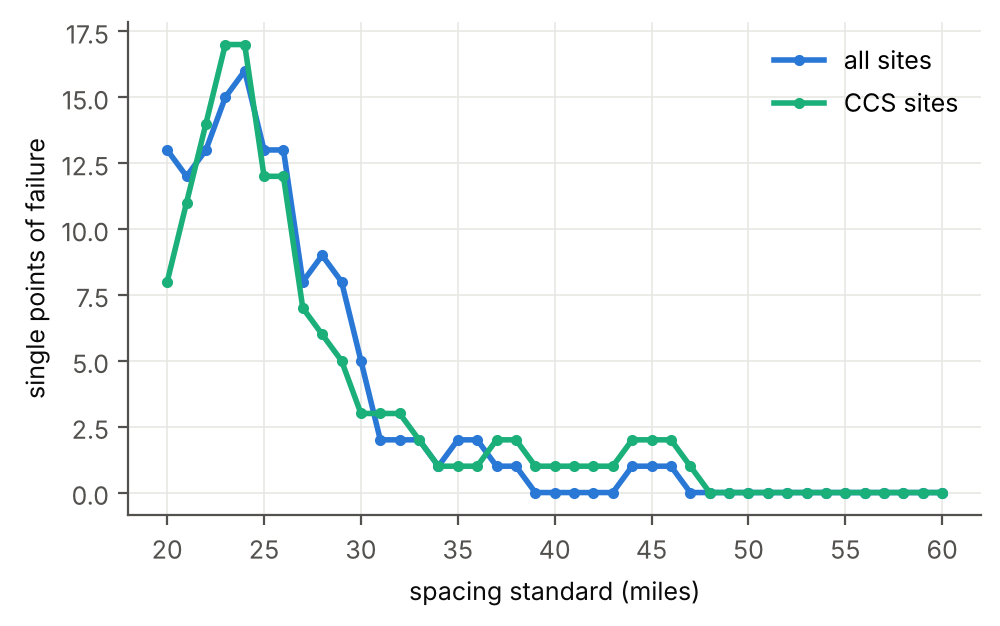

In [4]:
display(t("q2_critical_sites.csv"))
display(t("q2_big_or_small.csv"))
f("fig3_critical_sites.png")
f("figS2_cut_vertex_count.png")

### 3.1 Random failure and targeted attack

,network,miles,R_all,R_survivors,survivors_connected_p0.6
0,all,30,0.637763,0.886245,0.677311
1,all,35,0.671387,0.947352,0.829083
2,all,40,0.685032,0.973154,0.905590
3,all,45,0.693640,0.987376,0.953265
4,all,50,0.697674,0.994835,0.979504
5,ccs,30,0.616513,0.855934,0.678660
6,ccs,35,0.650161,0.915536,0.805406
7,ccs,40,0.678246,0.960794,0.897316
8,ccs,45,0.688513,0.979015,0.944126
9,ccs,50,0.696064,0.991766,0.967105


,miles,R_random,R_degree,R_betweenness,largest_after_15_betweenness,largest_after_30_betweenness,removals_to_drop_below_0.9
0,50,0.697674,0.695666,0.240167,0.980106,0.557029,17
1,30,0.637763,0.633370,0.148067,0.403183,0.295756,2


,degree,betweenness
0,Bronx,Schoharie
1,Bronx,Arkville
2,Bronx,Roscoe
3,The Bronx,Chittenango
4,The Bronx,New Baltimore
5,North New Hyde Park,Ravena
6,Jackson Heights,Little Falls
7,Queens,Little Falls
8,Roslyn Heights,Herkimer
9,Great Neck,Herkimer


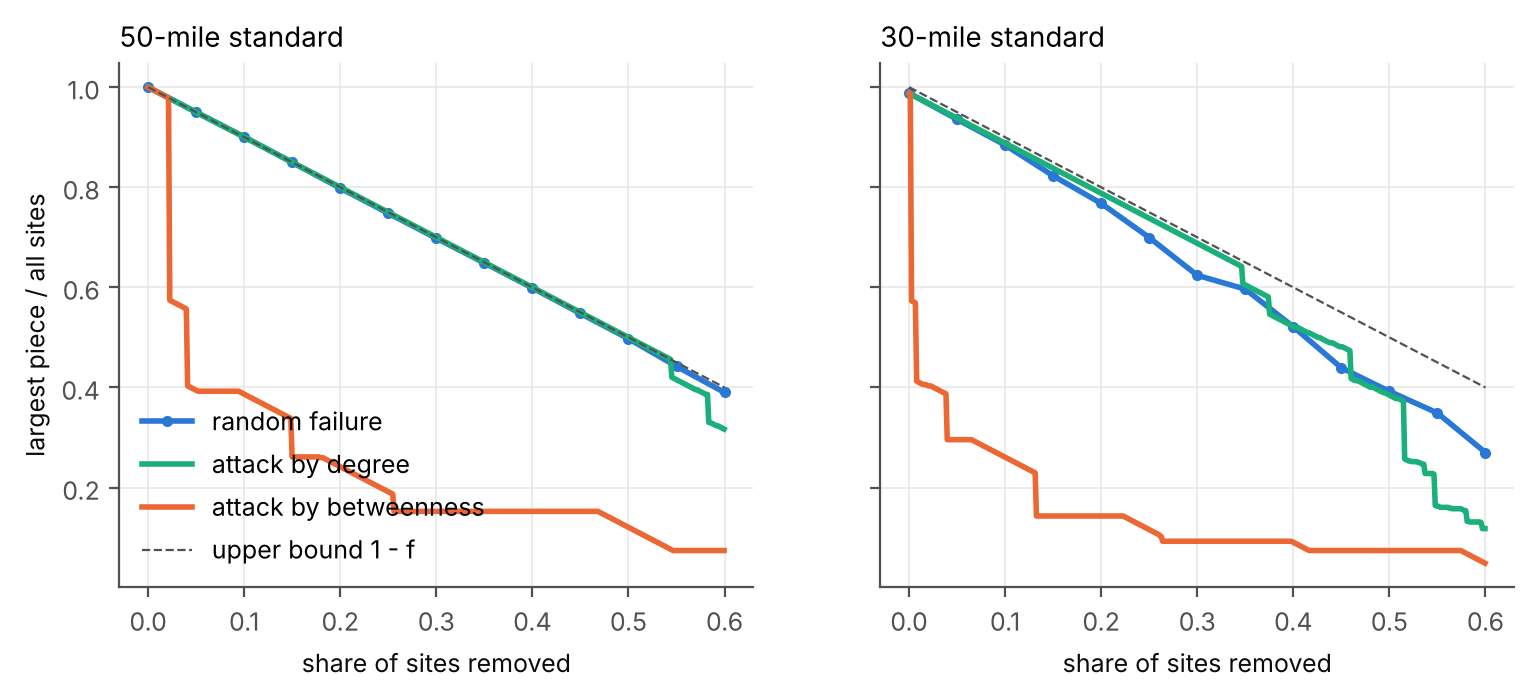

In [5]:
display(t("q2_random_failure.csv"))
display(t("q2_targeted_attack.csv"))
display(t("q2_attack_first15_50mi.csv"))
f("fig4_failure_attack.png")

### 3.2 Coverage is not connectivity

Coverage counts pairs of cities (362 places with 5,000+ people), plain and population-weighted, with two checks:
weights without New York City, and city access capped at 15 miles.

,miles,connectivity,coverage,coverage_weighted,coverage_weighted_excl_NYC,coverage_access15,coverage_weighted_access15
9,10,0.304,0.378,0.513,0.347,0.378,0.513
19,20,0.536,0.607,0.661,0.552,0.596,0.658
24,25,0.558,0.625,0.669,0.572,0.617,0.667
26,27,0.962,0.962,0.984,0.975,0.940,0.979
29,30,0.988,0.973,0.992,0.987,0.951,0.987
34,35,0.991,0.973,0.992,0.987,0.951,0.987
39,40,0.991,0.973,0.992,0.987,0.951,0.987
44,45,1.000,1.000,1.000,1.000,0.973,0.993
45,46,1.000,1.000,1.000,1.000,0.973,0.993
49,50,1.000,1.000,1.000,1.000,0.973,0.993


,name,pop,nearest
0,Ogdensburg city,10064,28.565587
1,Norwich city,7051,20.248668
2,Albion village,5637,18.325913
3,Medina village,6047,17.874881
4,Port Jervis city,8775,16.806188
5,Canton village,7155,11.960296
6,Hamlin CDP,5177,10.551793
7,Fort Drum CDP,15896,8.878025


,miles,name,city,coverage_lost,weighted_lost
0,30,"Chestertown, NY - Tesla Supercharger",Chestertown,0.005448,0.003864
1,30,"Peru, NY - Tesla Supercharger",Peru,0.005448,0.003864


,miles,R_random,R_degree,R_betweenness,Rw_random,Rw_degree,Rw_betweenness
0,50,0.994611,0.993631,0.471609,0.997945,0.994033,0.561526
1,30,0.898417,0.844714,0.366831,0.925452,0.876693,0.425114


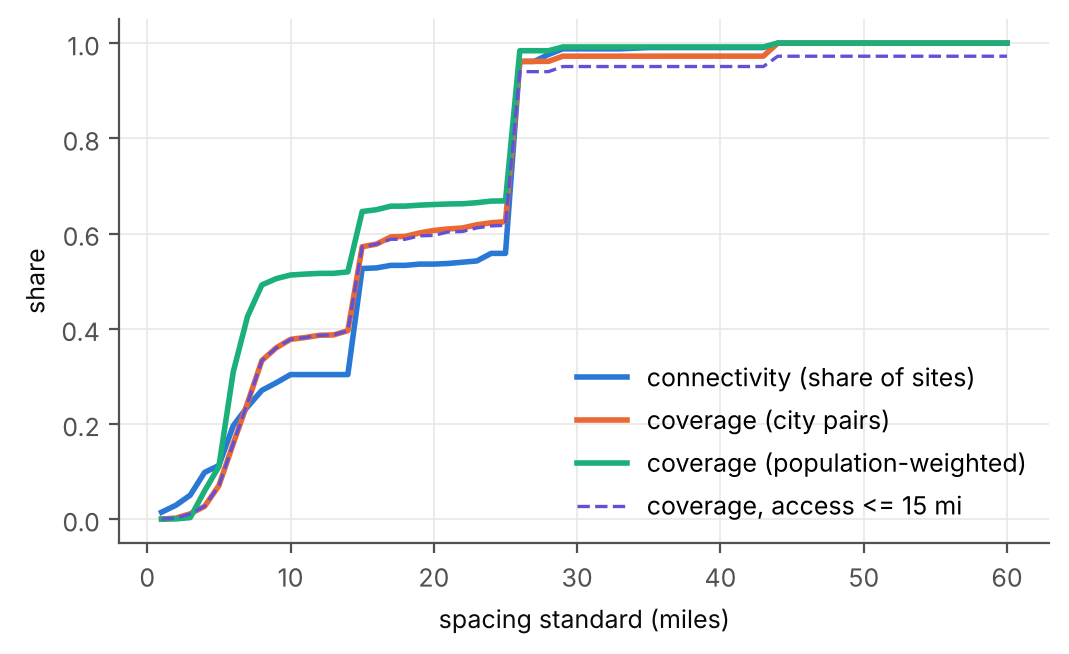

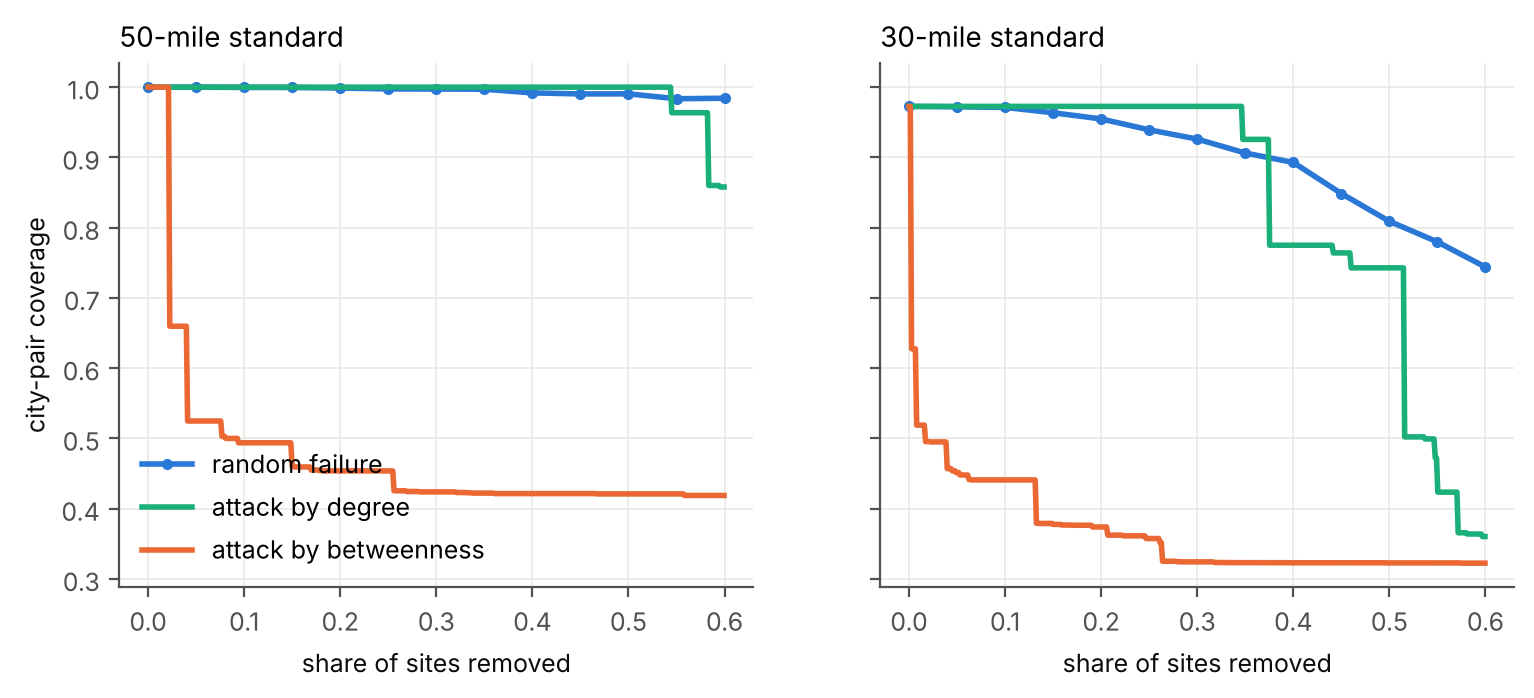

In [6]:
cv = t("coverage_curve.csv")
display(cv[cv["miles"].isin([10, 20, 25, 27, 30, 35, 40, 45, 46, 50])].round(3))
display(t("coverage_farthest_cities.csv"))
display(t("coverage_single_site_loss.csv"))
display(t("coverage_failure_attack.csv"))
f("fig5_coverage_curve.png")
f("figS3_coverage_attack.png")

### 3.3 Network structure (`run_structure.py`; report Sections 5, 6.1, 6.3 and 6.5)

Biconnectivity threshold, reliability of the single points of failure, global efficiency under attack,
betweenness variants, k-cores, random-walk spectral split, Leiden communities, centrality localisation,
EU AFIR standards, a band of winter losses and a region-stratified control.

,network,connectivity_threshold,biconnectivity_threshold,last_single_points_of_failure
0,"all sites, road",43.500000,46.200000,Saranac Lake
1,"CCS sites, road",43.500000,47.450000,Warrensburg
2,"all sites, straight x 1.2",43.115156,45.652971,Saranac Lake


,miles,cut_vertices,cities,source,p_unavailable,prob_any_cut_vertex_down,expected_sites_cut_off,prob_some_piece_splits_mc,survivors_cut_off_share_mc
0,30,5,Chestertown; Peru; Elizabethtown; Monticello; Roscoe,NEVI 97% uptime rule,0.030,0.141,1.440,0.157,0.002
1,30,5,Chestertown; Peru; Elizabethtown; Monticello; Roscoe,J.D. Power 2025 failed visits,0.140,0.530,6.720,0.594,0.018
2,30,5,Chestertown; Peru; Elizabethtown; Monticello; Roscoe,Rempel et al. 2022 Bay Area audit,0.275,0.800,13.200,0.908,0.059
3,35,2,Chestertown; TANNERSVILLE,NEVI 97% uptime rule,0.030,0.059,0.780,0.068,0.001
4,35,2,Chestertown; TANNERSVILLE,J.D. Power 2025 failed visits,0.140,0.260,3.640,0.318,0.007
5,35,2,Chestertown; TANNERSVILLE,Rempel et al. 2022 Bay Area audit,0.275,0.474,7.150,0.558,0.018
6,40,0,NaN,NEVI 97% uptime rule,0.030,0.000,0.000,0.005,0.000
7,40,0,NaN,J.D. Power 2025 failed visits,0.140,0.000,0.000,0.058,0.002
8,40,0,NaN,Rempel et al. 2022 Bay Area audit,0.275,0.000,0.000,0.230,0.006
9,45,1,Saranac Lake,NEVI 97% uptime rule,0.030,0.030,0.210,0.031,0.000


,miles,strategy,R_efficiency,fraction_to_0.2_relative_efficiency,relative_efficiency_after_5pct,E0_hops,E0_miles
0,50,random,0.517,0.56,0.902,0.332,0.030
1,50,degree,0.465,0.50,0.880,0.332,0.030
2,50,betweenness,0.275,0.26,0.643,0.332,0.030
3,50,harmonic,0.448,0.46,0.873,0.332,0.030
4,30,random,0.503,0.54,0.897,0.219,0.029
5,30,degree,0.427,0.44,0.862,0.219,0.029
6,30,betweenness,0.225,0.24,0.505,0.219,0.029
7,30,harmonic,0.416,0.42,0.861,0.219,0.029


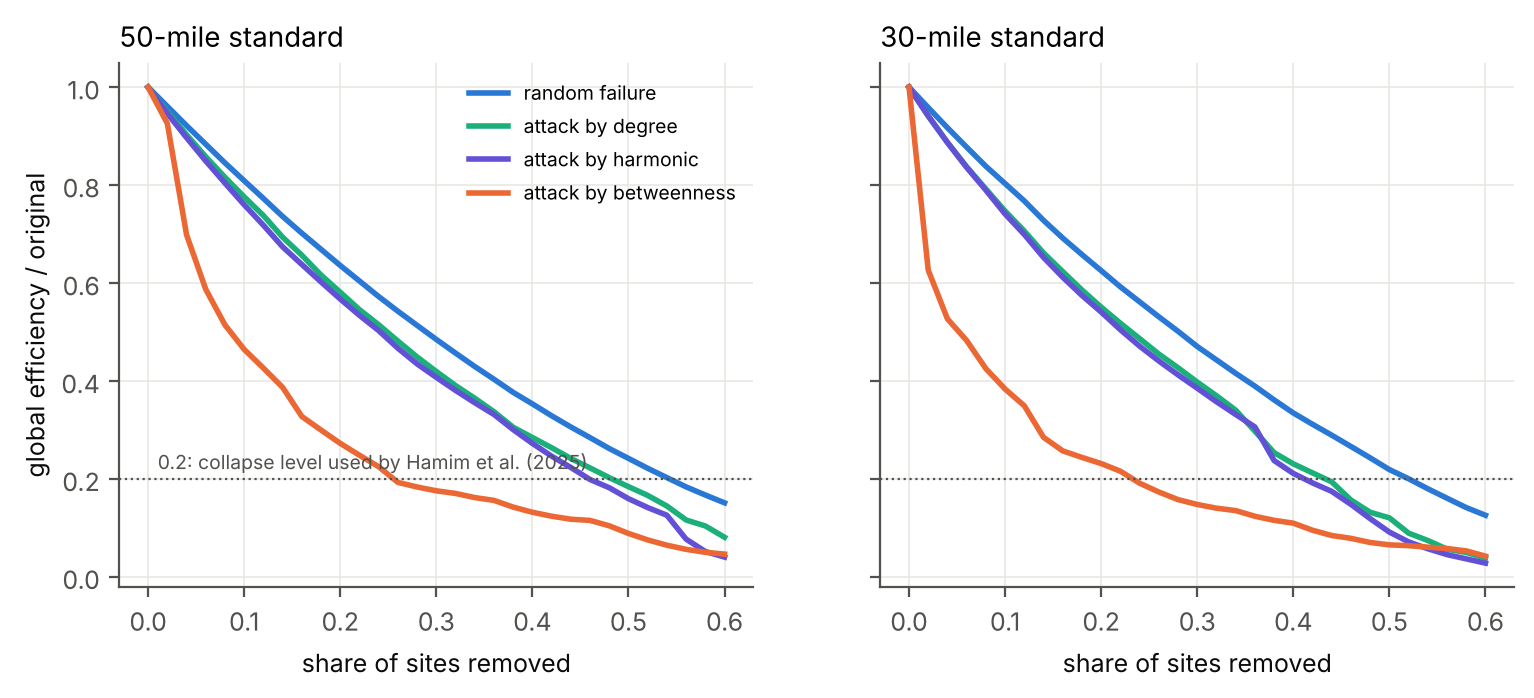

,miles,betweenness,rank,city,name,score,cut_vertex,near_nyc
0,30,hops,1,Little Falls,Iroquois Travel Plaza,71541.032596,False,False
1,30,hops,2,Fultonville,ONVO FULTONVILLE DC1,63803.578755,False,False
2,30,hops,3,Little Falls,Indian Castle Service Area,63199.037334,False,False
3,30,hops,4,Ravena,Crossroads Ford,55230.385410,False,False
4,30,hops,5,Fultonville,ONVO FULTONVILLE DC2,45746.724490,False,False
10,30,road miles,1,Ravena,Crossroads Ford,129323.000000,False,False
11,30,road miles,2,Fultonville,ONVO FULTONVILLE DC1,116407.941667,False,False
12,30,road miles,3,Fishkill,"Fishkill, NY - Tesla Supercharger",106496.316874,False,False
13,30,road miles,4,Little Falls,Indian Castle Service Area,105406.133333,False,False
14,30,road miles,5,Pattersonville,Pattersonville Service Plaza,101363.666667,False,False


,miles,group,sites,median_core,min_core,max_core,mean_core_percentile,median_ports
0,30,all sites,754,40.0,0,96,0.475,4.0
1,30,single points of failure,5,6.0,2,10,0.049,8.0
2,30,top 17 by betweenness,17,27.0,17,62,0.379,4.0
3,50,all sites,754,59.0,4,136,0.454,4.0
4,50,top 17 by betweenness,17,43.0,6,77,0.267,4.0


,miles,side_a_sites,side_b_sites,cut_links,normalised_cut,seam_cities
0,30,317,428,55,0.006603,Schenectady; Rotterdam; Amsterdam; Fultonville; Ballston Spa; Johnstown; Schoharie; Glenville; Pattersonville; Ballston
1,50,438,316,78,0.005535,Oneonta; Cooperstown; Ellenville; Amsterdam; Fultonville; Johnstown; Little Falls; Herkimer; Monticello; Roscoe


,miles,lambda2_now,lambda2_with_paul_smiths,tau_now,tau_with_paul_smiths,piece_now,piece_with_paul_smiths
0,40,0.99888,0.99888,895.50202,895.58993,747,755
1,44,0.99842,0.99842,634.02076,634.03435,754,755
2,45,0.99824,0.99824,567.52576,567.53484,754,755
3,50,0.99758,0.99758,414.00183,414.01231,754,755


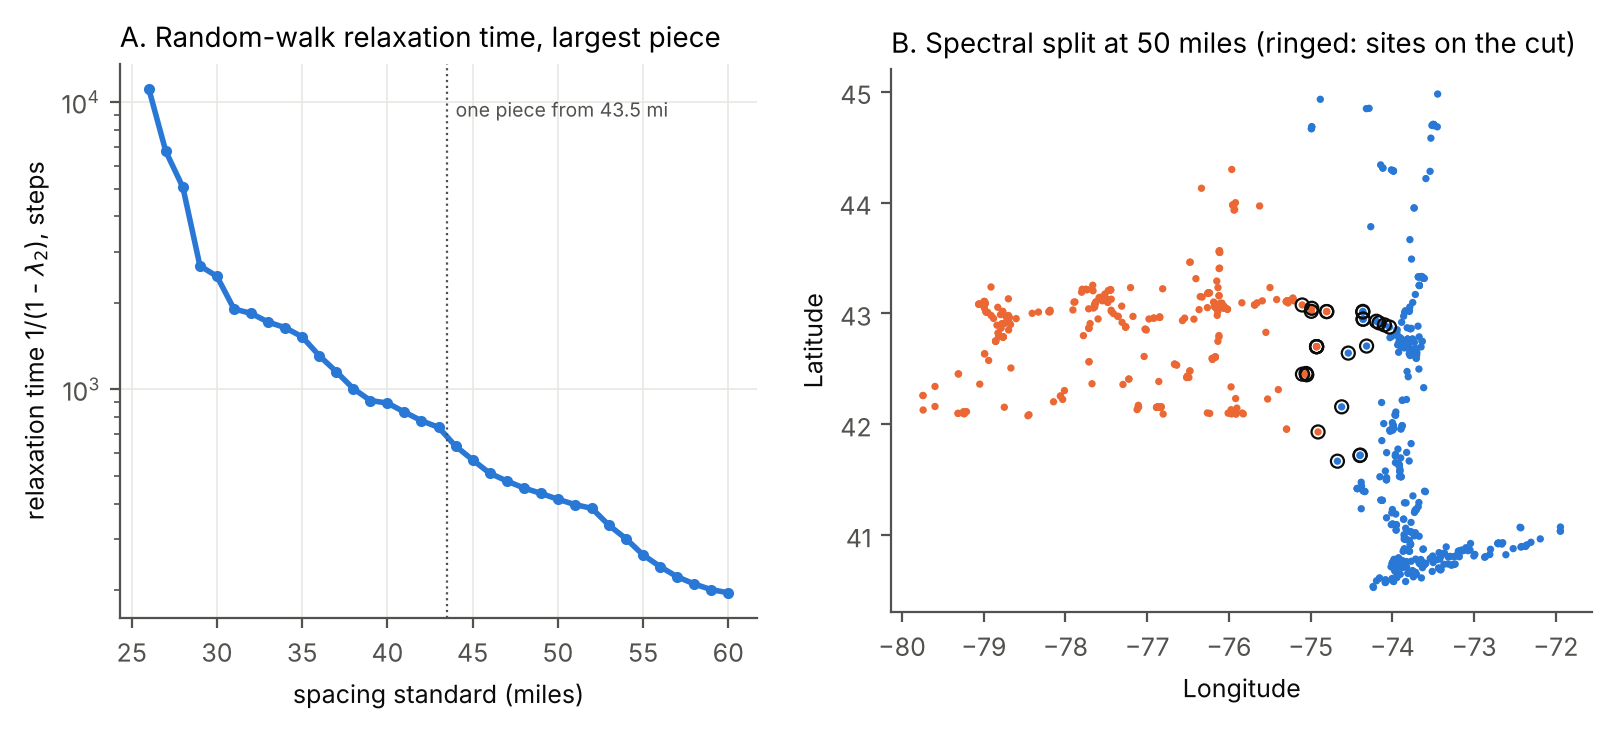

,miles,resolution,modularity,communities,largest_community,median_conductance,boundary_sites,top17_betweenness_on_boundary,cut_vertices_on_boundary,cut_vertices
0,30,0.5,0.657,12,234,0.011,116,13,1,5
1,30,1.0,0.694,15,149,0.025,278,13,1,5
2,30,2.0,0.657,16,101,0.034,296,13,1,5
3,50,0.5,0.600,6,238,0.043,302,14,0,0
4,50,1.0,0.606,6,225,0.045,372,14,0,0
5,50,2.0,0.497,48,153,1.000,536,15,0,0


,measure,share_of_score_within_60km_of_NYC,share_of_top10_within_60km_of_NYC,top5_cities
0,degree,0.416,1.0,Bronx; The Bronx; Bronx; The Bronx; Bronx
1,harmonic,0.269,1.0,Hartsdale; White Plains; Hastings on Hudson; Yonkers; White Plains
2,betweenness,0.086,0.0,Schoharie; Chittenango; Roscoe; Hamilton; Hudson
3,eigenvector,0.776,1.0,Great Neck; Roslyn Heights; North New Hyde Park; Bronx; Bronx
4,pagerank,0.251,0.0,Waterloo; Waterloo; Waterloo; Batavia; Batavia


friendship paradox: {'30': {'mean_degree': 57.30238726790451, 'mean_neighbour_degree': 60.960980726994265}, '50': {'mean_degree': 97.74535809018568, 'mean_neighbour_degree': 102.55387151997076}}


,name,pop,standard_to_reach_all,standard_to_reach_90pct
0,Massena village,10151,43.5,43.5
1,Ogdensburg city,10064,43.5,43.5
2,Malone village,5483,43.5,43.5
3,Potsdam village,8312,43.5,43.5
4,Canton village,7155,43.5,43.5
5,Fort Drum CDP,15896,43.5,28.5
6,Watertown city,24685,43.5,28.5
7,Orange Lake CDP,9770,43.5,26.0
8,Oneonta city,13079,43.5,26.0
9,Oneida city,10329,43.5,26.0


,standard,miles,pieces,cut_vertices,coverage,coverage_weighted,lower_bound,new_stations,feasible,where
0,"AFIR core, 60 km",37.282272,2,2,0.972682,0.991972,1,1,True,Paul Smiths
1,"AFIR low-traffic, 100 km",62.137119,1,0,1.000000,1.000000,0,0,True,NaN
2,former NEVI guidance,50.000000,1,0,1.000000,1.000000,0,0,True,NaN


,winter_case,range_loss,nominal_needed_connected,nominal_needed_biconnected,effective_miles_at_nominal_50,pieces_at_nominal_50,coverage_at_nominal_50
0,IEA lower (20%),0.20,54.38,57.75,40.0,2,0.97
1,30%,0.30,62.14,66.00,35.0,3,0.97
2,Recurrent (37%),0.37,69.05,73.33,31.5,5,0.97
3,AAA 20 F with heat (41%),0.41,73.73,78.31,29.5,5,0.97


,Unnamed: 0,real,random_mean,random_p05,random_p95,share_random_better
0,mst_threshold,43.834,41.001,33.842,46.624,0.60
1,coverage_30,0.962,0.915,0.622,0.967,0.18
2,coverage_40,0.973,0.982,0.967,1.000,0.42
3,weighted_coverage_30,0.984,0.943,0.666,0.988,0.18
4,cut_vertices_30,5.000,6.340,3.000,10.000,0.20
5,pieces_30,5.000,5.830,3.000,8.000,0.21


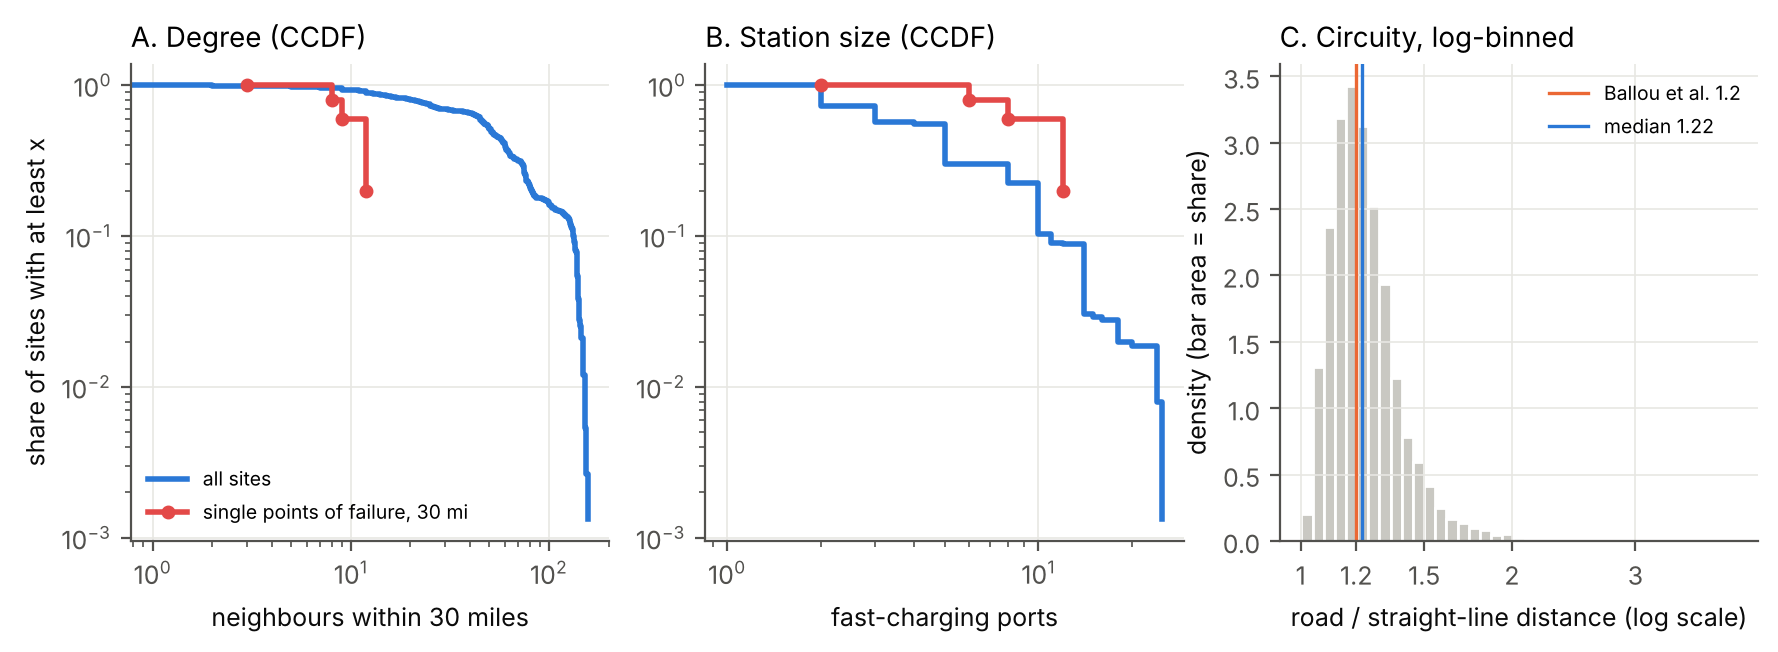

In [7]:
SS = json.load(open(ROOT / "results" / "structure_summary.json"))
display(t("s1_thresholds.csv"))
display(t("s2_reliability_cut_vertices.csv").round(3))
display(t("s3_efficiency.csv").round(3))
f("figS4_efficiency.png")
b4 = t("s4_betweenness_top10.csv"); display(b4[b4["rank"] <= 5])
display(t("s5_core_summary.csv").round(3))
display(t("s6_spectral_split.csv"))
display(t("s6_spectral_paul_smiths.csv").round(5))
f("figS5_spectral.png")
display(t("s7_communities.csv").round(3))
display(t("s8_centrality_localisation.csv").round(3))
print("friendship paradox:", SS["friendship_paradox"])
display(t("s9_city_standard_needed.csv").head(10))
display(t("s10_other_standards.csv"))
display(t("s11_winter_band.csv").round(2))
display(t("s12_control_stratified.csv").round(3))
f("figS6_distributions.png")

## 4. Q3: How many new stations does each standard need, and can New York afford them?

The report's cost curve is the exact one (`run_exact.py`): road distances to 2,703 candidate locations, solved as an
integer program (HiGHS via SciPy) with lazy vertex-separator cuts (`src/evnet/exact.py`). *Connectivity*: every pair of
sites that the full candidate graph can join must be joined. *Robustness*: in addition, no single station failure may
separate two sites that the full candidate graph keeps together after that failure. `lower_bound` equals `stations`
when the solver proved optimality.

,eps,objective,stations,lower_bound,iterations,cuts,status,seconds,network,sites,pieces,unreachable_sites,unreachable_cities,where,unprotectable_sites,cost_low_M,cost_central_M,cost_high_M,share_of_NEVI_central_pct
0,20.00,connectivity,17,17,41,202,optimal,5.4,all,754,26,44,Afton; Alexandria Bay; Cape Vincent; Champlain; Elizabethtown; Hancock; Lake Placid; Lewis; Malone; Massena; North H...,Liberty; Mt. Tremper; Fleischmanns; Spencer; Alfred; Cattaraugus; Cooperstown; Sharon Springs; Geneseo; Richfield Sp...,NaN,10.2,17.0,32.64,9.714286
1,25.00,connectivity,10,9,493,1178,time_limit,602.2,all,754,10,9,Hancock; Malone; Massena; Potsdam,Liberty; Shandaken; Cherry Valley; Boonville; Camden; Turin; North Creek; Lowville; Jay; Hogansburg,NaN,6.0,10.0,19.20,5.714286
2,30.00,connectivity,6,6,99,210,optimal,18.6,all,754,5,0,NaN,Delhi; North River; Evans Mills; Gouverneur; Canton; Hogansburg,NaN,3.6,6.0,11.52,3.428571
3,35.00,connectivity,2,2,1,3,optimal,0.2,all,754,3,0,NaN,Paul Smiths; Hogansburg,NaN,1.2,2.0,3.84,1.142857
4,37.28,connectivity,1,1,1,2,optimal,0.1,all,754,2,0,NaN,Ogdensburg,NaN,0.6,1.0,1.92,0.571429
5,40.00,connectivity,1,1,1,2,optimal,0.1,all,754,2,0,NaN,Ogdensburg,NaN,0.6,1.0,1.92,0.571429
6,45.00,connectivity,0,0,0,0,optimal,0.0,all,754,1,0,NaN,NaN,NaN,0.0,0.0,0.00,0.000000
7,50.00,connectivity,0,0,0,0,optimal,0.0,all,754,1,0,NaN,NaN,NaN,0.0,0.0,0.00,0.000000
8,55.00,connectivity,0,0,0,0,optimal,0.0,all,754,1,0,NaN,NaN,NaN,0.0,0.0,0.00,0.000000
9,60.00,connectivity,0,0,0,0,optimal,0.0,all,754,1,0,NaN,NaN,NaN,0.0,0.0,0.00,0.000000


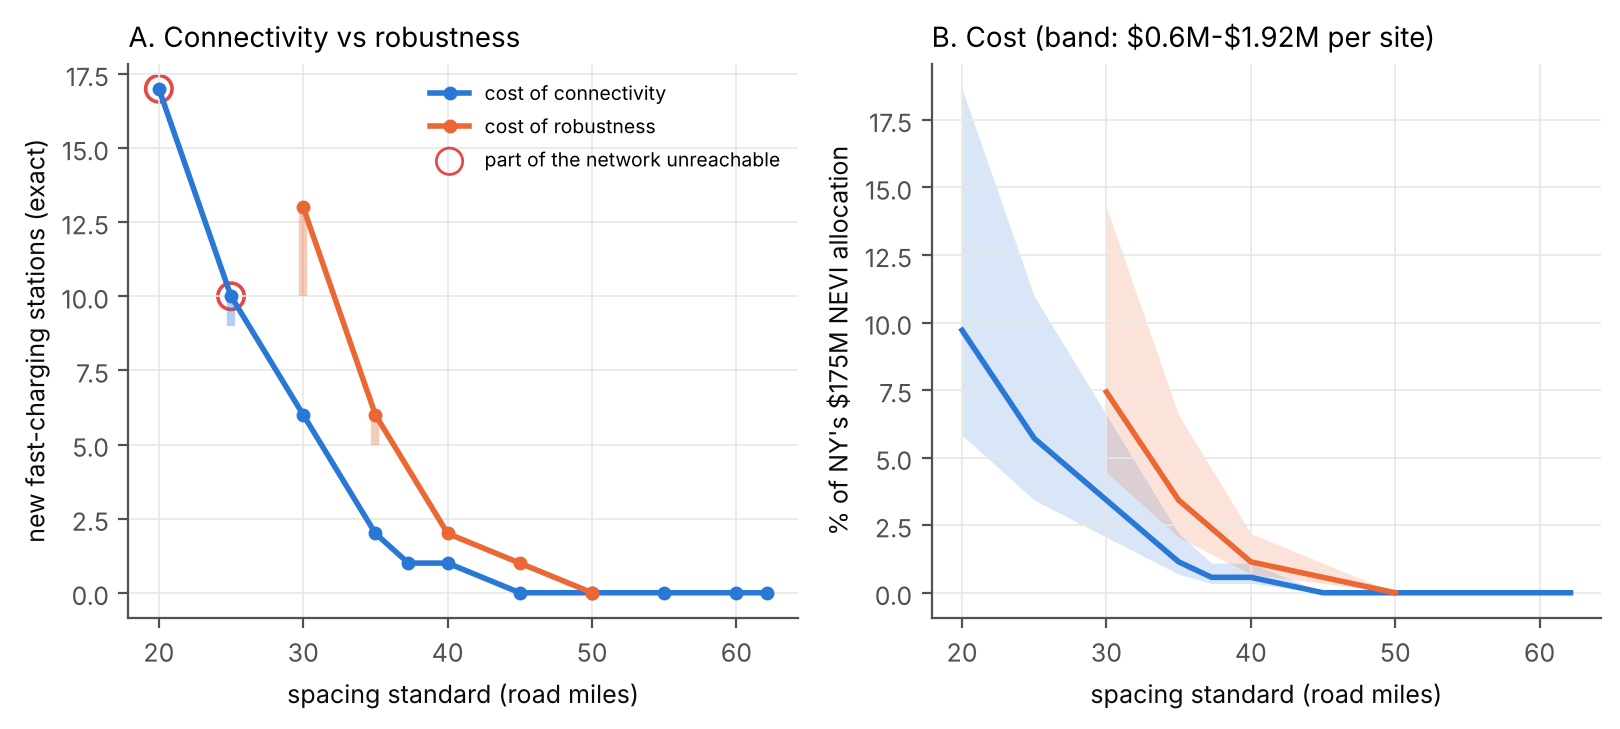

,eps,objective,stations,lower_bound,iterations,cuts,status,seconds,network,sites,pieces,unreachable_sites,unreachable_cities,where,unprotectable_sites,cost_low_M,cost_central_M,cost_high_M,share_of_NEVI_central_pct
0,30.0,connectivity,8,8,440,973,optimal,415.2,ccs,661,7,0,NaN,Downsville; Delhi; Chestertown; North River; Evans Mills; Gouverneur; Canton; Hogansburg,NaN,4.8,8.0,15.36,4.571429
1,40.0,connectivity,1,1,1,2,optimal,0.1,ccs,661,2,0,NaN,Ogdensburg,NaN,0.6,1.0,1.92,0.571429
2,50.0,connectivity,0,0,0,0,optimal,0.0,ccs,661,1,0,NaN,NaN,NaN,0.0,0.0,0.00,0.000000
3,60.0,connectivity,0,0,0,0,optimal,0.0,ccs,661,1,0,NaN,NaN,NaN,0.0,0.0,0.00,0.000000
4,50.0,robustness,0,0,0,0,optimal,0.0,ccs,661,1,0,NaN,NaN,0.0,0.0,0.0,0.00,0.000000
5,30.0,connectivity,13,11,552,1718,time_limit,601.2,hpc150,371,9,0,NaN,Downsville; Alfred; Delhi; Camden; Chestertown; Turin; North River; Evans Mills; Gouverneur; Jay; Canton; Hogansburg...,NaN,7.8,13.0,24.96,7.428571
6,40.0,connectivity,1,1,1,2,optimal,0.1,hpc150,371,2,0,NaN,Ogdensburg,NaN,0.6,1.0,1.92,0.571429
7,50.0,connectivity,0,0,0,0,optimal,0.0,hpc150,371,1,0,NaN,NaN,NaN,0.0,0.0,0.00,0.000000
8,60.0,connectivity,0,0,0,0,optimal,0.0,hpc150,371,1,0,NaN,NaN,NaN,0.0,0.0,0.00,0.000000
9,50.0,robustness,1,1,1,2,optimal,0.1,hpc150,371,1,0,NaN,Wanakena,0.0,0.6,1.0,1.92,0.571429


,network,sites,threshold_road_miles,weakest_link,cut_vertices_30,cut_vertices_50,pieces_50
0,all,754,43.5,Saranac Lake - Malone,5,0,1
1,ccs,661,43.5,Saranac Lake - Malone,3,0,1
2,hpc150,371,43.6,Saranac Lake - Malone,4,1,1
3,nevi_grade,239,47.4,Queensbury - North Hudson,7,1,1
4,working,747,43.5,Saranac Lake - Malone,5,0,1


In [8]:
tt("exact_cost_curve.csv")
f("fig10_cost_of_robustness.png")
tt("exact_subnetworks.csv")
tt("subnetwork_structure.csv")

### 4.1 Checks: Steiner heuristic on straight-line distances to candidates

`lower_bound` and `new_stations` bracket the minimum; `feasible = False` means some piece cannot be reached even if
every candidate were upgraded under the straight-line distance model.

,objective,miles,pieces_before,lower_bound,new_stations,feasible,v3_greedy,where,unreachable
0,network,20,26,3.0,10,False,NaN,Neversink; Cherry Valley; Cattaraugus; Cortland; Shandaken; Olean; Mount Morris; Cooperstown; Sterling; North Creek,Afton; Alexandria Bay; Cape Vincent; Champlain; Elizabethtown; Hancock; Lake Placid; Lewis; Malone; Massena; North H...
1,network,25,10,4.0,8,False,NaN,Neversink; Downsville; Cherry Valley; Newcomb; Jay; Lowville; Turin; Boonville,Malone; Massena; Potsdam
2,network,30,5,1.0,2,False,NaN,Windham; Newcomb,Malone; Massena; Potsdam
3,network,35,3,2.0,2,True,NaN,Paul Smiths; Massena,NaN
4,network,40,2,1.0,1,True,NaN,Paul Smiths,NaN
5,network,45,1,0.0,0,True,NaN,NaN,NaN
6,network,50,1,0.0,0,True,NaN,NaN,NaN
7,coverage,20,26,NaN,7,False,8.0,Cherry Valley; Silver Creek; Earlville; Cooperstown; Cattaraugus; Cortland; Mount Morris,Canton village; Fort Drum CDP; Malone village; Massena village; Ogdensburg city; Plattsburgh city; Potsdam village; ...
8,coverage,25,10,NaN,4,False,4.0,Cherry Valley; Lowville; Turin; Boonville,Canton village; Malone village; Massena village; Ogdensburg city; Potsdam village
9,coverage,30,5,NaN,0,False,3.0,NaN,Canton village; Malone village; Massena village; Ogdensburg city; Potsdam village


,objective,miles,lower_bound,new_stations,feasible,where
0,network,20,3.0,10,False,Neversink; Cherry Valley; Cattaraugus; Cortland; Shandaken; Olean; Geneseo; Cooperstown; Sterling; North River
1,network,25,4.0,8,False,Neversink; Downsville; Cherry Valley; Newcomb; Jay; Lowville; Turin; Boonville
2,network,30,3.0,5,True,Windham; Newcomb; Canton; Gouverneur; Hogansburg
3,network,35,2.0,2,True,Paul Smiths; Massena
4,network,40,1.0,1,True,Ogdensburg
5,network,45,0.0,0,True,NaN
6,network,50,0.0,0,True,NaN
7,coverage,20,NaN,7,False,Cherry Valley; Silver Creek; Earlville; Cooperstown; Cattaraugus; Cortland; Geneseo
8,coverage,25,NaN,4,False,Cherry Valley; Lowville; Turin; Boonville
9,coverage,30,NaN,4,True,Gouverneur; Ogdensburg; Waddington; Hogansburg


cost_level,central,high,low
miles,,,
20,5.71,10.97,3.43
25,4.57,8.78,2.74
30,1.14,2.19,0.69
35,1.14,2.19,0.69
40,0.57,1.10,0.34
45,0.00,0.00,0.00
50,0.00,0.00,0.00


sites the $175M allocation could fund: {'low': 291, 'central': 175, 'high': 91}


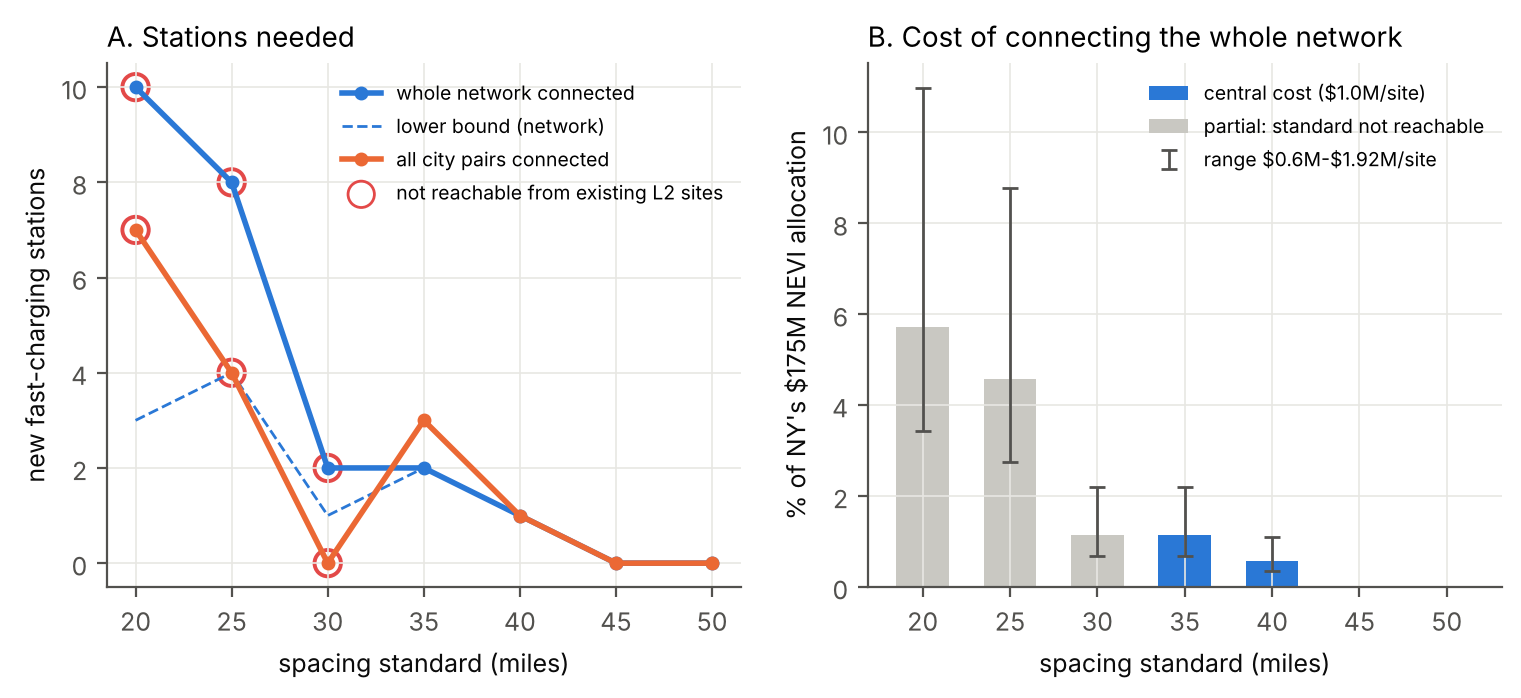

In [9]:
q3 = t("q3_cost_curve.csv")
display(q3)
display(t("q3_sensitivity_factor1.2.csv"))
b = t("q3_budget.csv")
display(b[b["objective"] == "network"].pivot(index="miles", columns="cost_level", values="share_of_NEVI_pct").round(2))
print("sites the $175M allocation could fund:", S["budget"]["sites_affordable"])
f("fig6_cost_curve.png")

### 4.2 Winter (41% range loss at 20°F with heat; AAA 2019)

nominal standard needed for one network in winter: 73.7 road miles


,nominal_miles,winter_effective_miles,pieces,connectivity,coverage,coverage_weighted
0,30,17.7,36,0.533156,0.593012,0.657506
1,35,20.7,23,0.537135,0.609587,0.662078
2,40,23.6,12,0.558355,0.622626,0.668198
3,45,26.6,8,0.961538,0.961709,0.984074
4,50,29.5,5,0.988064,0.972621,0.991970
5,55,32.5,5,0.988064,0.972621,0.991970
6,60,35.4,3,0.990716,0.972636,0.991971
7,65,38.4,2,0.990716,0.972682,0.991972
8,70,41.3,2,0.990716,0.972682,0.991972
9,75,44.3,1,1.000000,1.000000,1.000000


,nominal_miles,winter_effective_miles,pieces,lower_bound,new_stations,feasible,where
0,50,29.5,5,1,2,False,Windham; Newcomb
1,60,35.4,3,2,2,True,Paul Smiths; Massena
2,70,41.3,2,1,1,True,Ogdensburg


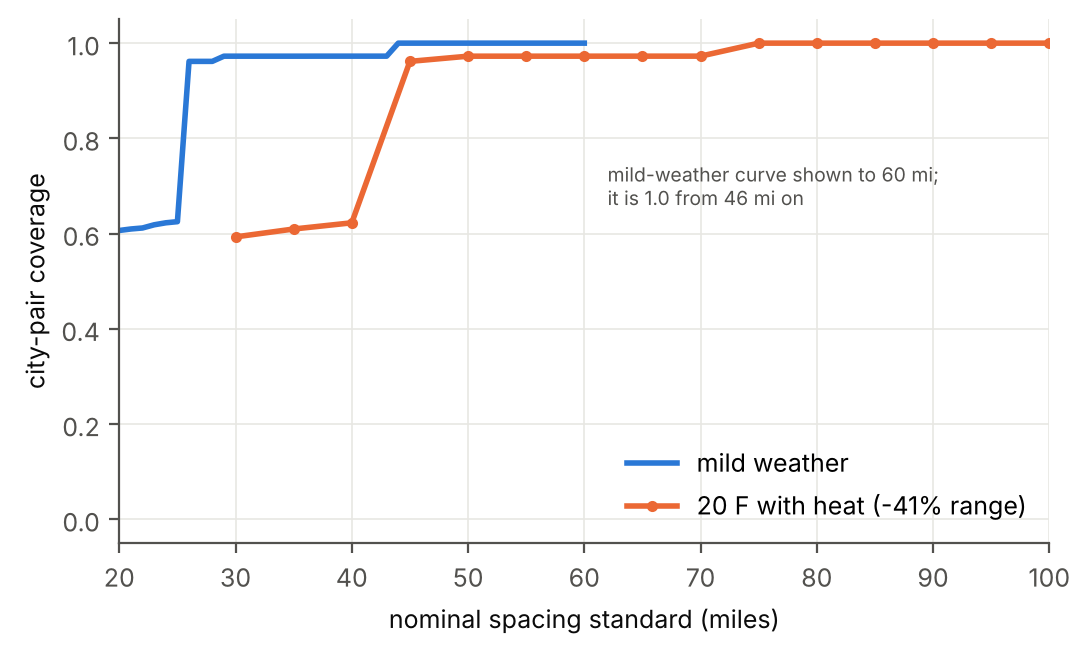

In [10]:
print(f"nominal standard needed for one network in winter: {S['winter_nominal_needed']:.1f} road miles")
display(t("winter.csv"))
display(t("winter_q3.csv"))
f("fig7_winter.png")

## 5. Control: is the network well sited?

,Unnamed: 0,real,random_mean,random_p05,random_p95,share_random_better
0,mst_threshold,43.834,45.096,36.560,53.921,0.43
1,coverage_30,0.962,0.770,0.599,0.956,0.02
2,coverage_40,0.973,0.971,0.956,1.000,0.43
3,weighted_coverage_30,0.984,0.809,0.654,0.980,0.02
4,cut_vertices_30,5.000,8.530,4.000,13.000,0.07
5,pieces_30,5.000,8.430,5.000,12.000,0.01


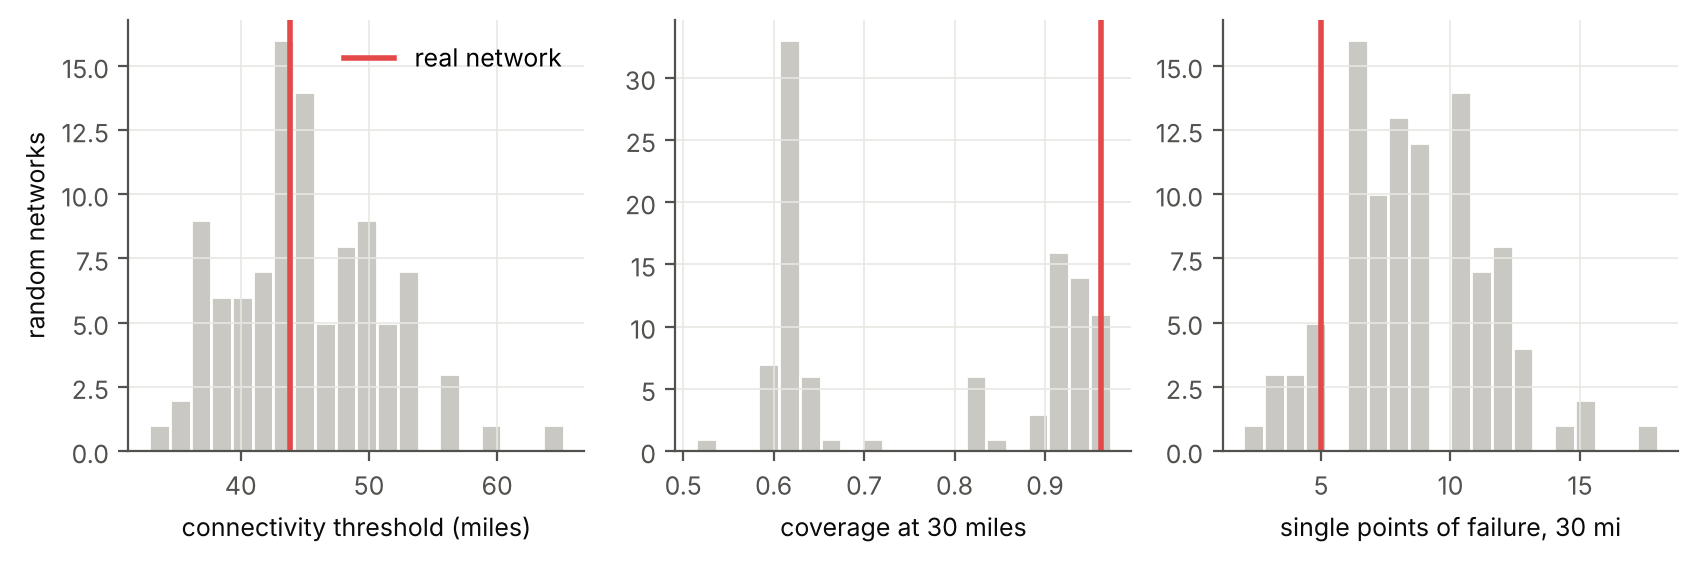

In [11]:
display(t("control_summary.csv").round(3))
f("fig8_control.png")

## 6. Robustness: October 13, 2026 station list

In [12]:
display(t("robustness_snapshot.csv"))

,snapshot,sites,threshold,weakest_link,cut_30,cut_35,cut_45,new_stations_30,new_stations_35,new_stations_40
0,"Sep 23, 2026",754,43.833742,Saranac Lake - Malone,Roscoe; Chestertown; Elizabethtown; Lewis; Peru,Chestertown; Malone; Massena,Saranac Lake,3,1,1
1,"Oct 13, 2026",793,43.833742,Saranac Lake - Malone,Roscoe; Chestertown; Lewis; Peru,Malone; Massena,Saranac Lake,3,1,1


## 7. Further checks (`run_extended.py`; report Section 8.4)

### 7.1 Trips along real roads and the Hanig et al. coverage measure

,network,vehicle,season,usable_range_mi,trips_ok_gravity_weighted,trips_ok_aadt_weighted,trips_ok_unweighted,trips_failing
0,all,smallest 2024 EV (114 mi),mild,114.0,0.891442,0.645854,0.642939,622
1,all,smallest 2024 EV (114 mi),winter 20F,67.3,0.595695,0.382255,0.394948,1054
2,all,150 mi,mild,150.0,0.891518,0.674210,0.679104,559
3,all,150 mi,winter 20F,88.5,0.888137,0.625081,0.603330,691
4,all,median MY2024 EV (283 mi),mild,283.0,0.998031,0.966345,0.979334,36
5,all,median MY2024 EV (283 mi),winter 20F,167.0,0.891518,0.674532,0.680827,556
6,hpc150,smallest 2024 EV (114 mi),mild,114.0,0.891442,0.645689,0.641791,624
7,hpc150,smallest 2024 EV (114 mi),winter 20F,67.3,0.586187,0.311449,0.278990,1256
8,hpc150,150 mi,mild,150.0,0.891442,0.651702,0.652124,606
9,hpc150,150 mi,winter 20F,88.5,0.887954,0.617071,0.590700,713


,from,to,miles,req_range_all,req_range_hpc150,req_range_nevi_grade
0,Coram CDP,Jamestown city,423.000,528.876953,528.876953,528.876953
1,Centereach CDP,Jamestown city,417.100,521.589355,521.589355,521.589355
2,Holbrook CDP,Jamestown city,416.283,520.617676,520.617676,520.617676
3,Bay Shore CDP,Jamestown city,409.978,512.844238,512.844238,512.844238
4,Central Islip CDP,Jamestown city,409.587,512.358398,512.358398,512.358398
5,Brentwood CDP,Jamestown city,406.798,508.957520,508.957520,508.957520
6,Commack CDP,Jamestown city,406.369,507.985840,507.985840,507.985840
7,Deer Park CDP,Jamestown city,403.885,505.070801,505.070801,505.070801
8,Dix Hills CDP,Jamestown city,401.217,501.669922,501.669922,501.669922
9,Huntington Station CDP,Jamestown city,398.421,498.269043,498.269043,498.269043


,gateway,trips,max_req_all,max_req_hpc150,max_req_nevi
0,Champlain–Lacolle border (I-87),71,201.906738,201.906738,201.906738
1,Lewiston–Queenston bridge,61,264.580078,264.580078,264.580078
2,Massena–Cornwall crossing (Rooseveltown),68,195.104980,206.765137,206.765137
3,Ogdensburg–Prescott bridge,68,381.667480,381.667480,381.667480
4,Thousand Islands Bridge (I-81),69,335.998535,335.998535,335.998535


,network,gap_threshold_miles,aadt_weighted_share,length_share,corridor_cells
0,all,25,0.796571,0.381339,10825
1,all,30,0.841070,0.465035,10825
2,all,40,0.897026,0.557229,10825
3,all,50,0.906535,0.607760,10825
4,all,60,0.910133,0.619584,10825
5,hpc150,25,0.650217,0.277413,10825
6,hpc150,30,0.730710,0.353349,10825
7,hpc150,40,0.794325,0.440370,10825
8,hpc150,50,0.811756,0.494873,10825
9,hpc150,60,0.826259,0.535427,10825


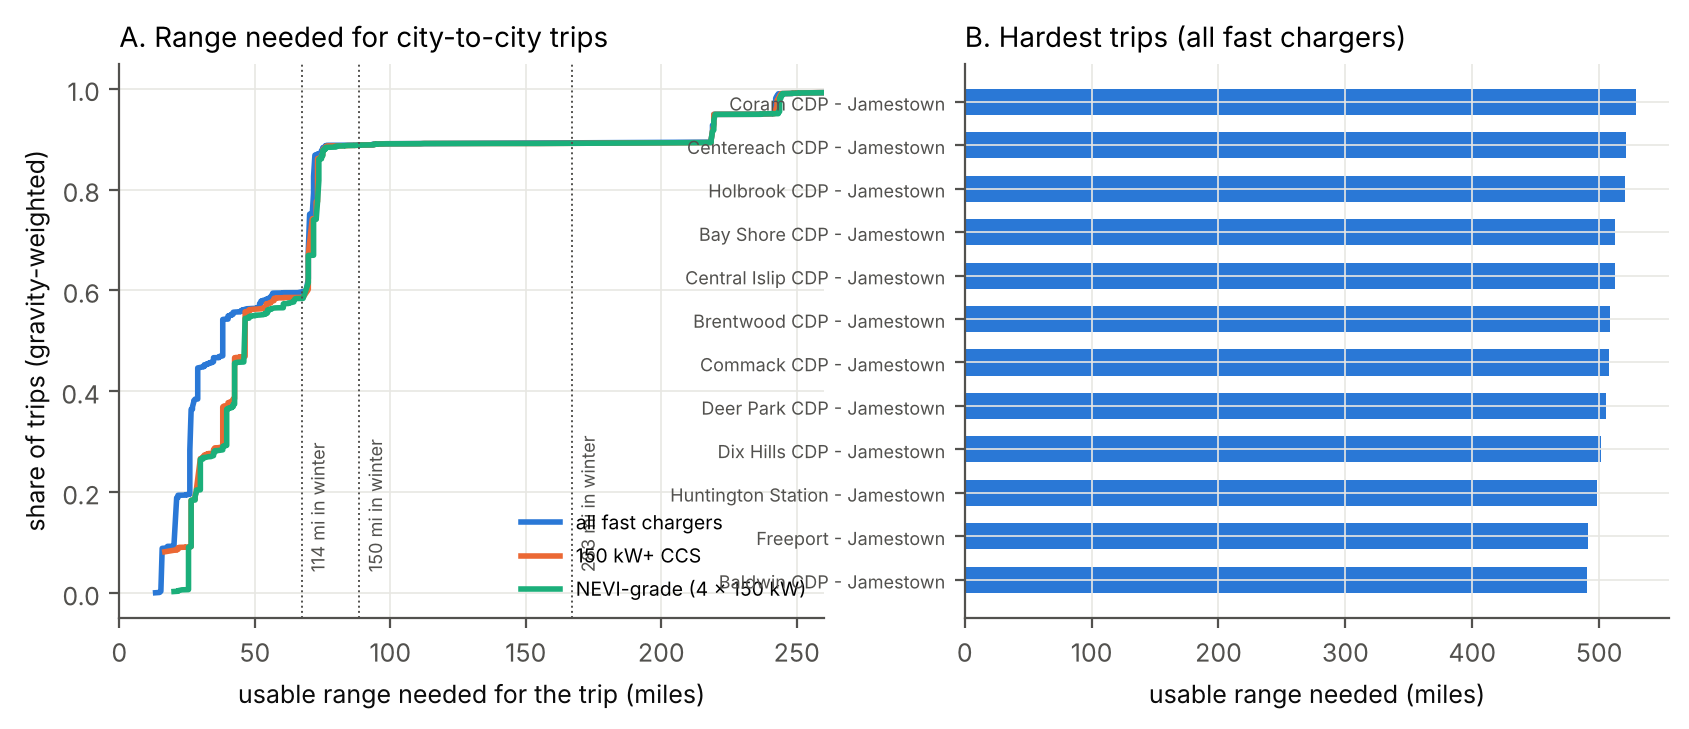

In [13]:
tt("trips_feasibility.csv")
tt("trips_hardest.csv")
tt("trips_border.csv")
tt("hanig_consecutive_coverage.csv")
f("fig11_trip_ranges.png")

### 7.2 How the network grew, 2015-2026

,year,sites,threshold_road_miles,weakest_link,largest_share_50,pieces_50,cut_vertices_50,cut_vertices_30,coverage_50,coverage_weighted_50,stations_needed_50,stations_lower_bound_50,solver_status,unreachable_sites_50
0,2015,14,1000000.00,Queens - Binghamton,0.500000,8,0,3,0.412911,0.525745,8,7,time_limit,0
1,2016,22,1000000.00,Queens - Binghamton,0.545455,9,2,3,0.473883,0.564864,10,8,time_limit,0
2,2017,31,1000000.00,Queens - Buffalo,0.483871,9,4,3,0.484765,0.568808,7,7,optimal,0
3,2018,53,1000000.00,Queens - Buffalo,0.584906,9,2,3,0.484765,0.568808,7,7,optimal,0
4,2019,72,1000000.00,New York City - Salamanca,0.611111,9,3,0,0.493809,0.570858,8,7,time_limit,0
5,2020,95,1000000.00,New York City - Salamanca,0.610526,9,3,5,0.497681,0.572023,6,6,optimal,0
6,2021,130,1000000.00,New York City - Salamanca,0.607692,8,4,4,0.498033,0.572153,5,5,optimal,0
7,2022,194,65.55,Clay - Watertown,0.664948,5,6,4,0.627125,0.666652,3,3,optimal,0
8,2023,309,50.95,Lake Placid - Plattsburgh,0.974110,2,3,5,0.967310,0.988119,1,1,optimal,0
9,2024,465,43.50,Saranac Lake - Malone,1.000000,1,1,7,1.000000,1.000000,0,0,optimal,0


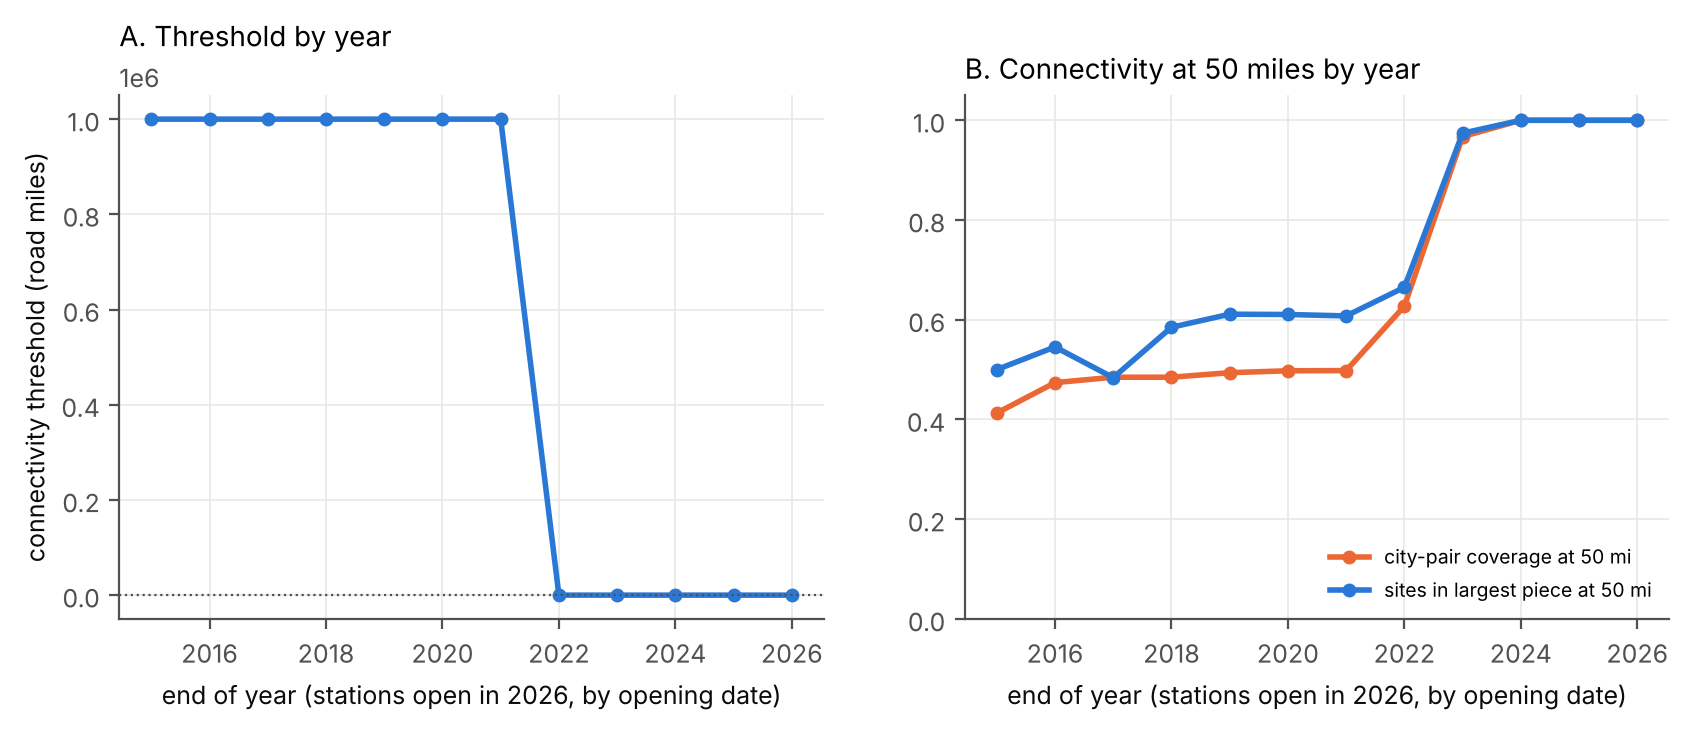

In [14]:
tt("history_by_year.csv")
f("fig12_history.png")

### 7.3 Reliability: unavailable stations and regional outages

In [15]:
tt("reliability_regional_outages.csv")
tt("random_failure_ci.csv")

,miles,outage_radius_mi,sites_lost_mean,sites_lost_p95,survivors_connected_regional,survivors_connected_independent,coverage_regional_mean,coverage_independent_mean,coverage_regional_p05,coverage_independent_p05,share_draws_losing_coverage_regional,share_draws_losing_coverage_independent
0,50,10,24.533333,57.00,0.999991,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
1,50,25,69.200000,144.00,0.972844,0.999843,0.946644,0.999782,0.646478,1.000000,0.316667,0.010000
2,50,50,136.483333,244.05,0.946247,0.999144,0.724576,0.998927,0.342802,0.999180,0.970000,0.050000
3,30,10,27.323333,64.00,0.985703,0.985598,0.971279,0.972094,0.972621,0.967172,0.033333,0.100000
4,30,25,66.786667,145.05,0.856082,0.973670,0.738880,0.965065,0.463591,0.961754,0.843333,0.263333
5,30,50,132.633333,244.00,0.806335,0.957952,0.540428,0.954166,0.186599,0.940264,1.000000,0.470000


,miles,p,survivors_connected_mean,p2.5,p97.5
0,50,0.00,1.000000,1.000000,1.000000
1,50,0.05,1.000000,1.000000,1.000000
2,50,0.10,0.999825,1.000000,1.000000
3,50,0.15,0.999382,0.992217,1.000000
4,50,0.20,0.999307,0.993225,1.000000
5,50,0.25,0.998948,0.991029,1.000000
6,50,0.30,0.998204,0.965645,1.000000
7,50,0.35,0.996708,0.960784,1.000000
8,50,0.40,0.995022,0.957243,1.000000
9,50,0.45,0.993327,0.957600,1.000000


### 7.4 Random baselines with 95% confidence intervals and random-geometric-graph theory

In [16]:
tt("baselines_with_ci.csv")
import json
p = ROOT / "results" / "extended_summary.json"
if p.exists():
    print(json.dumps(json.load(open(p)).get("rgg", {}), indent=1))

,baseline,measure,real,random_mean,random_p2.5,random_p97.5,share_random_better,share_ci_low,share_ci_high
0,uniform over all charging locations,threshold_miles,43.833742,45.468652,34.990294,58.841478,0.380,0.315589,0.448934
1,uniform over all charging locations,coverage_30,0.961754,0.794276,0.597489,0.961755,0.025,0.010725,0.057179
2,uniform over all charging locations,pieces_30,5.000000,8.435000,4.975000,12.025000,0.025,0.010725,0.057179
3,uniform over all charging locations,cut_vertices_30,5.000000,8.485000,3.000000,14.000000,0.075,0.045975,0.120045
4,population-weighted,threshold_miles,43.833742,97.736902,65.382653,153.392523,0.000,0.000000,0.018846
5,population-weighted,coverage_30,0.961754,0.465885,0.439251,0.563073,0.000,0.000000,0.018846
6,population-weighted,pieces_30,5.000000,8.295000,6.000000,11.000000,0.005,0.000883,0.027774
7,population-weighted,cut_vertices_30,5.000000,1.425000,0.000000,5.000000,0.945,0.904212,0.969015
8,corridor-restricted (within 1 mi of a major route),threshold_miles,43.833742,47.176186,37.943019,61.488519,0.225,0.172623,0.287742
9,corridor-restricted (within 1 mi of a major route),coverage_30,0.961754,0.684987,0.487809,0.908696,0.000,0.000000,0.018846


{
 "n": 754,
 "area_sq_mi": 47126,
 "connectivity_radius_straight": 11.480888038303712,
 "connectivity_radius_road": 14.006683406730529,
 "percolation_radius_straight": 9.474454744058162,
 "percolation_radius_road": 11.558834787750957,
 "observed_threshold_road": 43.5,
 "observed_giant_component_jump_road": 26,
 "mean_degree_at": {
  "10": 15.286472148541113,
  "15": 25.312997347480106,
  "20": 36.254641909814325,
  "24": 44.771883289124666,
  "25": 46.83819628647215,
  "26": 48.95225464190982,
  "30": 57.30238726790451,
  "43": 82.95225464190982,
  "44": 85.15915119363395,
  "50": 97.74535809018568
 },
 "density_mean_per_sq_mi": 0.01599966048465815,
 "density_near_weakest_link": 0.003692394679731972,
 "inhomogeneous_prediction_road": 29.156583808072554
}


## 8. Optional: learning to place stations (`run_learning.py`, needs PyTorch; not in the report)

In [17]:
tt("learning_summary.csv")
f("fig13_learning.png")

learning_summary.csv not found: run the script that makes it
fig13_learning.png not found: run the script that makes it


## 9. Summary (matches the report's abstract and answers)

- **Q1.** One network from **43.5 road miles**; weakest link Saranac Lake – Malone, then Malone – Massena (37.2),
  Arkville – Tannersville (34.7) and Chestertown – Indian Lake (33.3). No single point of failure from **46.2 miles**.
  The two large regions join at 26 miles.
- **Q2.** At 30 miles five sites are single points of failure (Chestertown, Peru, Elizabethtown, Monticello, Roscoe),
  four of them Tesla Superchargers: isolated (median degree 9 vs 50, core number 6 vs 40), not small (median ports 8 vs 4).
  With 14% unavailability at least one is down 53% of the time. High-betweenness sites sit on an east–west seam found
  by the spectral split and Leiden boundaries; 17 betweenness removals (2.3%) cut the largest piece to 57% at 50 miles,
  while degree attack does no more than random failure.
- **Coverage.** At 30–43 miles 99% of sites but 97.3% of city pairs are connected; every pair from 44 miles.
- **Q3 (exact, road distances).** 0 stations at 45–50 miles, 1 at 37.3–40 (Ogdensburg or Paul Smiths), 2 at 35
  (Paul Smiths, Hogansburg), 6 at 30, at most 6.6% of the $175M NEVI allocation. Cost of robustness: 0 at 50, 1 at 45,
  2 at 40, 6 at 35, 13 at 30. Below 30 miles parts of the North Country cannot be reached from existing locations.
- **Winter.** One network needs a nominal 54–74 road miles for 20–41% range loss.
- **Control.** Better than 98% of 100 random networks at 30 miles; no better than chance on the overall threshold;
  much of the advantage comes from how many chargers each region received.